In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,precision_score, recall_score , f1_score,
    confusion_matrix,classification_report,roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print('Libraries imported successfully!')

In [ ]:
df = pd.read_csv(r"C:\Users\maitt\Downloads\Loan_default.csv\Loan_default.csv")

In [ ]:
df.head()

In [ ]:
df.describe()

In [ ]:
df.duplicated().sum()

In [ ]:
df['Default'].value_counts()

In [ ]:
df['Default'].value_counts().plot(kind='bar')

In [ ]:
df.select_dtypes(exclude='str').columns

In [ ]:
numerical_cols=['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

fig, axs= plt.subplots(3,3,figsize=(10,10))   
axs= axs.flatten() 
for index, column_name in enumerate(numerical_cols):
    sns.boxplot(data=df,y=column_name,x='Default',ax=axs[index])
    axs[index].set_title(f'{column_name}vs Default')
    plt.tight_layout() 

In [ ]:
numerical_cols=['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

fig, axs= plt.subplots(3,3,figsize=(10,10))   
axs= axs.flatten() 
for index, column_name in enumerate(numerical_cols):
    sns.boxplot(data=df,y=column_name,x='Default',ax=axs[index])
    axs[index].set_title(f'{column_name}vs Default')
    axs[index].set_xticklabels(['No Default','Default'])
    plt.tight_layout()

In [ ]:
# CORRELATION
plt.figure(figsize=(10,8))
df[numerical_cols]

In [ ]:
plt.figure(figsize=(10,8))
df[numerical_cols+['Default']].corr()

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr())

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr())
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
# Data preprocessing
df.drop('LoanID',axis=1,inplace=True)

In [ ]:
df.head()

In [ ]:
X= df.drop('Default',axis=1)
Y= df['Default']

In [ ]:
categorical_column=X.select_dtypes(include='str').columns.to_list()
numerical_column=X.select_dtypes(exclude='str').columns.to_list()
label_encoders={}

for col in categorical_column:
    le=LabelEncoder()
    X[col]=le.fit_transform(X[col].astype(str))
    print(f'encoded{col}:{dict(zip(le.classes_,le.transform(le.classes_)))}')

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(
    X,Y,test_size=0.2,random_state=22
)

In [ ]:
scaler = StandardScaler()
X_train_scaled=x_train.copy()
X_test_scaled=x_test.copy()

X_train_scaled[numerical_cols]=scaler.fit_transform(x_train[numerical_column])
X_test_scaled[numerical_cols]=scaler.fit_transform(x_test[numerical_column])

In [ ]:
lr= LogisticRegression(class_weight='balanced',
max_iter=100,solver= 'saga', n_jobs=-1)
lr.fit(X_train_scaled,y_train)
lr.pred=lr.predict(X_test_scaled)
y_pred_prob=lr.predict(X_test_scaled)
from sklearn.metrics import (ConfusionMatrixDisplay,
classification_report, accuracy_score,
precision_score,recall_score,roc_auc_score)

In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(x_train,y_train)

In [ ]:
y_pred = model.predict(x_test)

In [ ]:
print("x_test:",len(x_test))
print("y_test:",len(y_test))
print("Y_pred:",len(y_pred))

In [ ]:
print(f'accuracy_score: {accuracy_score(y_test,y_pred)}')
print(f'precision_score: {precision_score(y_test,y_pred)}')
print(f'recall_score: {recall_score(y_test,y_pred)}')
print(f'f1 score: {f1_score(y_test,y_pred)}')
print(f'roc_auc_score: {roc_auc_score(y_test,y_pred)}')

In [ ]:
print(classification_report(y_test,y_pred,
target_names=['No default', 'Default']))

In [ ]:
cm= confusion_matrix(y_test,y_pred)
dis=ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=['No Default','Default'])
dis.plot()
plt.show()

In [ ]:
fpr,tpr,thresolds=roc_auc(y_test,y_pred_proba)
plt.figure(figsize=(3,3))
plt.plot(fpr,tpr,lw=2)

In [ ]:
coef_df=pd.DataFrame({
    'Columns':x_train.columns,
    'coefficient':lr.coef_[0],
})

In [ ]:
coef_df

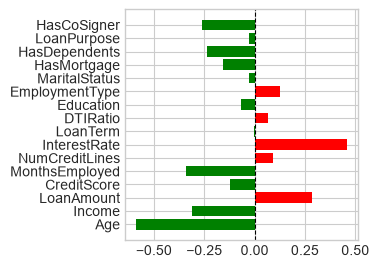

In [35]:
plt.figure(figsize=(3,3))
color=['r' if c>0 else 'g'for c in coef_df['coefficient']]
plt.barh(coef_df['Columns'], coef_df['coefficient'], color=color)
plt.axvline(x=0, color='black', linewidth = 0.8, linestyle='--')
plt.show()

In [41]:
x_test.iloc[:2,:]

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
191605,48,104051,139338,325,1,1,24.53,24,0.84,2,3,1,0,1,0,0
236232,59,40930,129079,441,35,1,23.52,60,0.63,0,2,0,1,0,4,1


In [37]:
#from  
import joblib

joblib.dump(lr,'logistic_regression.pkl')

['logistic_regression.pkl']

In [40]:
model.predict(x_test.iloc[:2,:])

array([1, 1])

In [38]:
model=joblib.load('logistic_regression.pkl')